Introduction to Transpilation (Part 2)
The documentation you shared explains transpilation in more detail than the previous introduction. It introduces three important concepts:
1. ISA (Instruction Set Architecture) – which instructions a quantum device supports.
2. Transpiler stages – the six stages used to prepare a circuit.
3. PassManager and StagedPassManager – how Qiskit organizes and executes circuit transformations.

QFlowPilot research
This is where the topic becomes particularly important.

Your QFlowPilot system aims to make runtime decisions based on application quality, execution time, and quantum resource cost.

Transpilation gives you information about the circuit's hardware-specific implementation.

Qiskit transpilation pipeline
1. Init — Prepare and decompose the input circuit.
2. Layout — Map logical qubits to physical qubits.
3. Routing — Insert SWAP gates when connectivity requires them.
4. Translation — Convert operations into native hardware gates.
5. Optimization — Simplify and improve the circuit.
6. Scheduling — Arrange operations according to hardware timing.

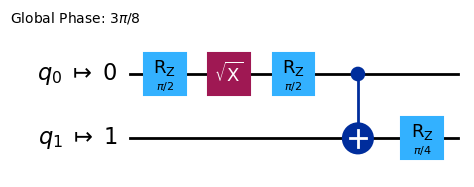

In [5]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.providers.fake_provider import GenericBackendV2

qc = QuantumCircuit(2)

qc.h(0)
qc.cx(0, 1)
qc.t(1)


backend = GenericBackendV2(15)

pass_manager = generate_preset_pass_manager(
    optimization_level=1,
    backend=backend
)

transpiled_circuit = pass_manager.run(qc)

transpiled_circuit.draw("mpl")

2. Init stage
The Init stage prepares the circuit for later transformations.

The documentation highlights two purposes:
1. It provides a place to include custom initial optimizations.
2. It decomposes operations involving more than two qubits into one- and two-qubit operations, because most layout and routing algorithms work with these smaller operations.
For example, consider a Toffoli gate:

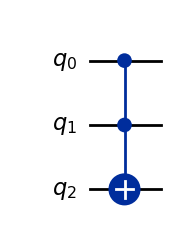

In [17]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(3)

qc.ccx(0, 1, 2)

qc.draw("mpl")

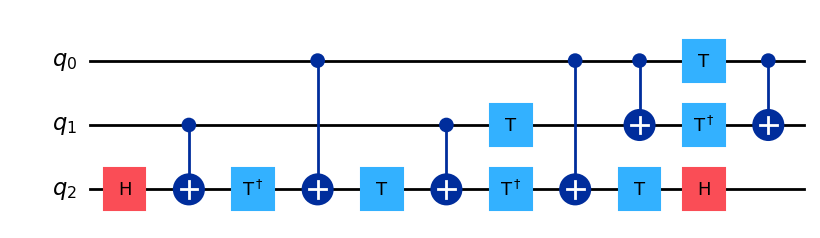

In [16]:
decomposed = qc.decompose()

decomposed.draw("mpl")

Layout stage — Logical qubits vs physical qubits
This is one of the most important concepts.

A quantum circuit contains logical qubits:
\[
Q_L=\{q_0,q_1,q_2,q_3\}
\]

A physical quantum computer contains actual hardware qubits:
\[
Q_P=\{p_0,p_1,p_2,\ldots,p_{n-1}\}
\]

The layout stage establishes a mapping:
\[
L:Q_L\rightarrow Q_P
\]

For example:
Logical qubit	Physical qubit
q0	p5
q1	p6
q2	p9
q3	p10

The choice matters because physical qubits have different connectivity and calibration properties.
Layout algorithms in your documentation
Three important methods are described.

A. TrivialLayout

Maps logical qubits to physical qubits using the same indices.

Example:
\[
[0,1,2,3]\rightarrow[0,1,2,3]
\]

It is a simple mapping and, according to the documentation, is used in optimization level 1 as a historical initial attempt to find a perfect layout.

B. VF2Layout

This method treats layout selection as a subgraph-isomorphism problem.

In simple words:
- It examines the circuit's interaction graph.
- It examines the hardware connectivity graph.
- It tries to find a mapping where required interactions are directly supported.
- If multiple valid mappings exist, a scoring heuristic selects one with lower average error.
A layout requiring no routing SWAP gates is called a perfect layout in this context.

C. SabreLayout

If a perfect layout cannot be found, Qiskit can use a heuristic approach.

SabreLayout starts with an initial mapping and repeatedly applies the SabreSwap algorithm to search for a good layout.

It is not guaranteed to find the globally optimal layout.
Algorithm	Main purpose
TrivialLayout	Simple same-index mapping
VF2Layout	Find a connectivity-compatible mapping
SabreLayout	Heuristically search for a good layout

Note: The exact passes used depend on optimization level and circuit features. The documentation specifically describes DenseLayout as another heuristic option for certain level-1 circuits containing control-flow operations.

Routing stage — Why are SWAP gates necessary?
Suppose your hardware has this connectivity:

Available connections:
\[
(0,1),(1,2),(2,3)
\]

Now suppose your circuit requires:
\[
CX(0,3)
\]

But qubits 0 and 3 are not directly connected.

The routing stage must make the required interaction possible using the available connections.

One possible strategy is to move quantum states using SWAP gates.

A SWAP operation exchanges two qubit states:
\[
SWAP|a,b\rangle=|b,a\rangle
\]

A SWAP can be implemented using three CNOT gates:
\[
SWAP=CX_{01}CX_{10}CX_{01}
\]

Why SWAP gates are expensive
3 CX gates
Required to decompose one SWAP in the example from the documentation
More two-qubit operations generally mean more opportunities for hardware errors and longer execution time.

What is SabreSwap?
The documentation introduces SabreSwap as a stochastic heuristic routing algorithm.

It searches for a good sequence of SWAP operations.

However, finding the globally optimal SWAP mapping is NP-hard. Therefore, Qiskit uses a heuristic rather than solving every instance optimally.

This creates an important observation:

Running the same circuit multiple times can produce different transpiled circuits.

The reason is the stochastic routing process.

The documentation's GHZ example runs transpilation 100 times with different seeds and measures the resulting circuit depths.

In [18]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.providers.fake_provider import GenericBackendV2

backend = GenericBackendV2(15)

ghz = QuantumCircuit(15)
ghz.h(0)
ghz.cx(0, range(1, 15))

depths = []

for seed in range(100):

    pm = generate_preset_pass_manager(
        optimization_level=1,
        backend=backend,
        layout_method="trivial",
        seed_transpiler=seed
    )

    transpiled = pm.run(ghz)
    depths.append(transpiled.depth())

print(depths)

[17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17, 17]


Text(0, 0.5, 'Counts')

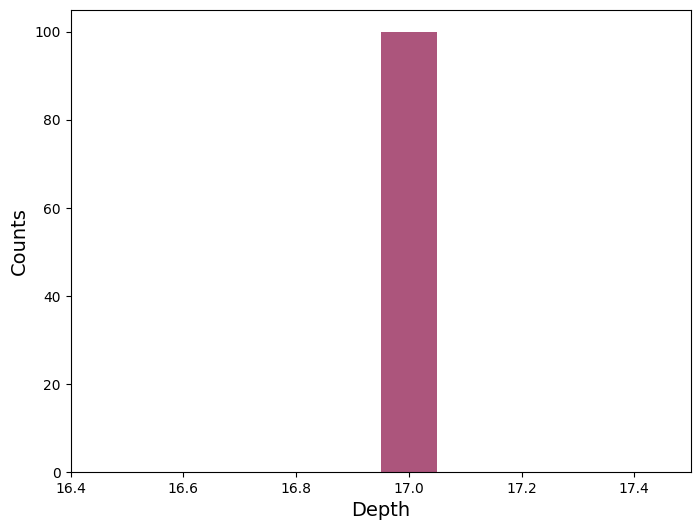

In [23]:
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.providers.fake_provider import GenericBackendV2

backend = GenericBackendV2(15)


ghz = QuantumCircuit(15)
ghz.h(0)
ghz.cx(0, range(1, 15))

depths = []
for seed in range(100):
    pass_manager = generate_preset_pass_manager(
        optimization_level=1,
        backend=backend,
        layout_method="trivial",  # Fixed layout mapped in circuit order
        seed_transpiler=seed,  # For reproducible results
    )
    depths.append(pass_manager.run(ghz).depth())

plt.figure(figsize=(8, 6))
plt.hist(depths, align="left", color="#AC557C")
plt.xlabel("Depth", fontsize=14)
plt.ylabel("Counts", fontsize=14)

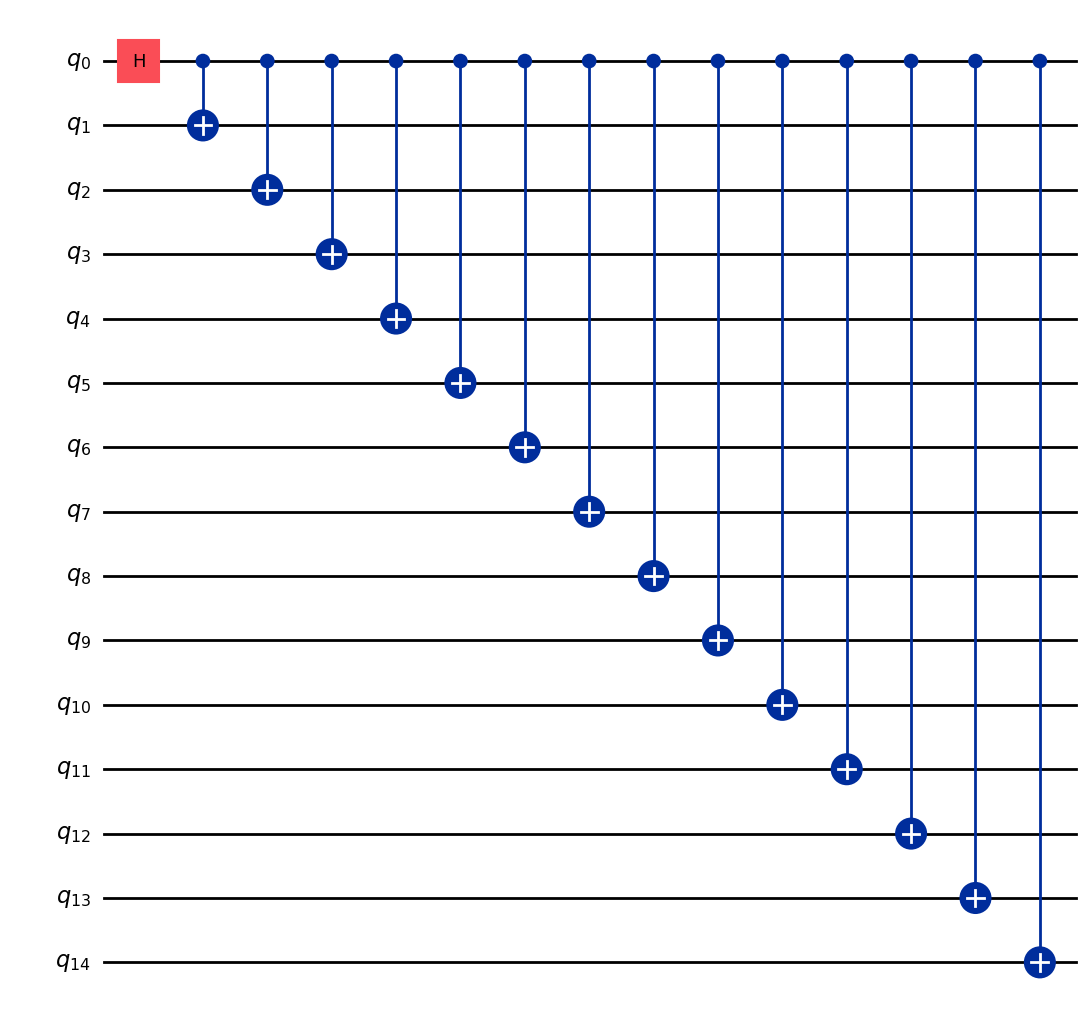

In [24]:
ghz.draw("mpl", idle_wires=False)

mportant research insight
This is useful for QFlowPilot.

You should not assume that one transpilation run always finds the best circuit.

You could investigate:
- Circuit depth across multiple transpilation seeds.
- Two-qubit gate count across seeds.
- SWAP count across seeds.
- Transpilation time.
- Estimated hardware quality of each resulting circuit.
For a fair experiment, record the random seed and compare the same optimization and backend configurations.

5. Translation stage — Native basis gates
Different quantum devices support different gate sets.

For example, the documentation uses a backend with native instructions including:
\[
\{CX,Delay,Id,Measure,Reset,RZ,SX,X\}
\]

Suppose you create a circuit containing:

qc = QuantumCircuit(2)

qc.swap(0, 1)

In [19]:
qc = QuantumCircuit(2)

qc.swap(0, 1)

native gates:['cx', 'delay', 'id', 'measure', 'reset', 'rz', 'sx', 'x']


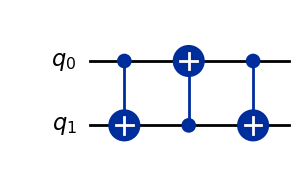

In [26]:
print("native gates:" + str(sorted(backend.operation_names)))
qc = QuantumCircuit(2)
qc.swap(0, 1)
qc.decompose().draw("mpl")

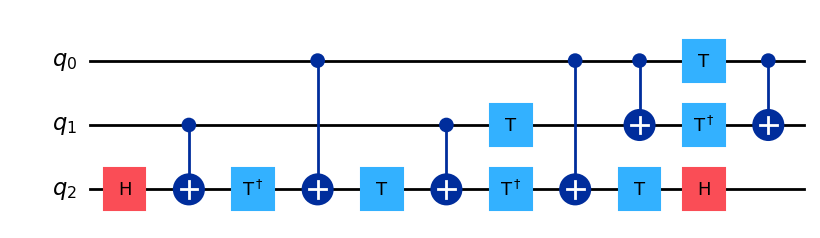

In [27]:
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)
qc.decompose().draw("mpl")

Optimization stage
After routing and translation, the circuit may contain many operations.

The optimization stage attempts to reduce unnecessary operations and improve the implementation.

Your documentation describes different methods at different optimization levels.
Level	Main optimization passes described in the source
0	Minimal optimization
1	Optimize1qGatesDecomposition, CXCancellation
2	Optimize1qGatesDecomposition, CommutativeCancellation
3	Collect2qBlocks, ConsolidateBlocks, UnitarySynthesis, Optimize1qGateDecomposition, CommutativeCancellation

Let's understand two examples.
Example A: CNOT cancellation
Two consecutive CNOT gates with the same control and target cancel:
\[
CX_{01}CX_{01}=I
\]

In [20]:
from qiskit import QuantumCircuit

qc = QuantumCircuit(2)

qc.cx(0, 1)
qc.cx(0, 1)

print("Before:", qc.count_ops())

optimized = qc.decompose()

print("Decomposed:", optimized.count_ops())

Before: OrderedDict([('cx', 2)])
Decomposed: OrderedDict([('cx', 2)])


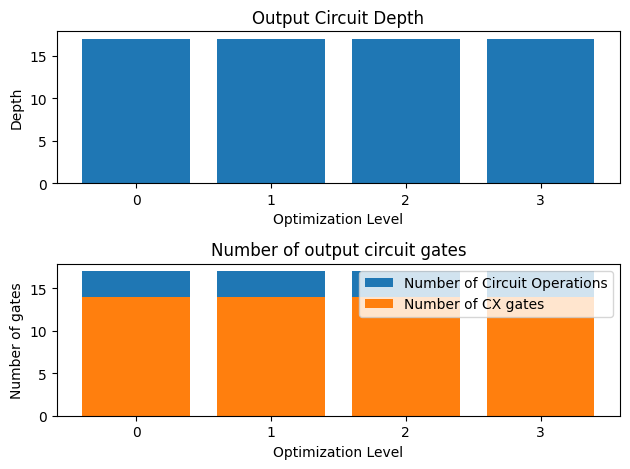

In [28]:
ghz = QuantumCircuit(15)
ghz.h(0)
ghz.cx(0, range(1, 15))

depths = []
gate_counts = []
multiqubit_gate_counts = []
levels = [str(x) for x in range(4)]
for level in range(4):
    pass_manager = generate_preset_pass_manager(
        optimization_level=level,
        backend=backend,
        seed_transpiler=1234,
    )
    circ = pass_manager.run(ghz)
    depths.append(circ.depth())
    gate_counts.append(sum(circ.count_ops().values()))
    multiqubit_gate_counts.append(circ.count_ops()["cx"])

fig, (ax1, ax2) = plt.subplots(2, 1)
ax1.bar(levels, depths, label="Depth")
ax1.set_xlabel("Optimization Level")
ax1.set_ylabel("Depth")
ax1.set_title("Output Circuit Depth")
ax2.bar(levels, gate_counts, label="Number of Circuit Operations")
ax2.bar(levels, multiqubit_gate_counts, label="Number of CX gates")
ax2.set_xlabel("Optimization Level")
ax2.set_ylabel("Number of gates")
ax2.legend()
ax2.set_title("Number of output circuit gates")
fig.tight_layout()
plt.show()

The cancellation itself is performed by the appropriate optimization pass, not by decompose() alone.
Example B: Single-qubit gate optimization
Consider two consecutive rotations around the Z axis:
\[
RZ(\theta)RZ(\phi)=RZ(\theta+\phi)
\]

Instead of executing two separate gates, they can be combined into one.

This reduces the number of operations.
Does optimization level 3 always produce the best circuit?
No.

Higher optimization levels use more sophisticated optimization techniques, but they also require more compilation effort.

The final circuit can still be affected by heuristic decisions, particularly routing.

For research, compare actual output metrics rather than assuming level 3 is always best.

7. Scheduling stage
The documentation explains that scheduling does not run by default.

You must explicitly request it.

For example:

In [21]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.providers.fake_provider import GenericBackendV2

ghz = QuantumCircuit(5)

ghz.h(0)
ghz.cx(0, range(1, 5))

backend = GenericBackendV2(5)

pm = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend,
    scheduling_method="asap",
    seed_transpiler=1234
)

scheduled_circuit = pm.run(ghz)

print(scheduled_circuit.draw())

global phase: π/4
          ┌────────────────┐                 ┌───┐┌─────────────────┐»
q_1 -> 0 ─┤ Delay(221[dt]) ├─────────────────┤ X ├┤ Delay(6551[dt]) ├»
         ┌┴────────────────┤                 └─┬─┘└──────┬───┬──────┘»
q_2 -> 1 ┤ Delay(3461[dt]) ├───────────────────┼─────────┤ X ├───────»
         ├─────────────────┤                   │         └─┬─┘       »
q_4 -> 2 ┤ Delay(6830[dt]) ├───────────────────┼───────────┼─────────»
         ├─────────────────┤                   │           │         »
q_3 -> 3 ┤ Delay(4398[dt]) ├───────────────────┼───────────┼─────────»
         └───┬─────────┬───┘┌────┐┌─────────┐  │           │         »
q_0 -> 4 ────┤ Rz(π/2) ├────┤ √X ├┤ Rz(π/2) ├──■───────────■─────────»
             └─────────┘    └────┘└─────────┘                        »
«                                                    
«q_1 -> 0 ───────────────────────────────────────────
«         ┌─────────────────┐                        
«q_2 -> 1 ┤ Delay(5614[dt]) ├──────────

In [22]:
from qiskit import QuantumCircuit
from qiskit.transpiler import generate_preset_pass_manager
from qiskit.providers.fake_provider import GenericBackendV2

# Create backend
backend = GenericBackendV2(15)

# Create GHZ circuit
ghz = QuantumCircuit(15)
ghz.h(0)
ghz.cx(0, range(1, 15))

# Store results
results = []

for level in range(4):

    pm = generate_preset_pass_manager(
        optimization_level=level,
        backend=backend,
        seed_transpiler=1234
    )

    circ = pm.run(ghz)

    results.append({
        "level": level,
        "depth": circ.depth(),
        "total_gates": sum(circ.count_ops().values()),
        "cx_gates": circ.count_ops().get("cx", 0),
        "operations": dict(circ.count_ops())
    })

for result in results:
    print(result)

{'level': 0, 'depth': 17, 'total_gates': 17, 'cx_gates': 14, 'operations': {'cx': 14, 'rz': 2, 'sx': 1}}
{'level': 1, 'depth': 17, 'total_gates': 17, 'cx_gates': 14, 'operations': {'cx': 14, 'rz': 2, 'sx': 1}}
{'level': 2, 'depth': 17, 'total_gates': 17, 'cx_gates': 14, 'operations': {'cx': 14, 'rz': 2, 'sx': 1}}
{'level': 3, 'depth': 17, 'total_gates': 17, 'cx_gates': 14, 'operations': {'cx': 14, 'rz': 2, 'sx': 1}}


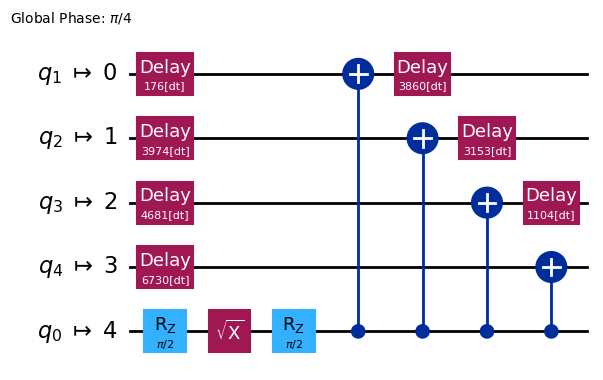

In [30]:
ghz = QuantumCircuit(5)
ghz.h(0)
ghz.cx(0, range(1, 5))


# Use fake backend
backend = GenericBackendV2(5)

# Run with optimization level 3 and 'asap' scheduling pass
pass_manager = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend,
    scheduling_method="asap",
    seed_transpiler=1234,
)


circ = pass_manager.run(ghz)
circ.draw(output="mpl", idle_wires=False)

What should QFlowPilot learn from this lesson?
For QFlowPilot, the important outcome is not simply knowing how to transpile a circuit. It is understanding how transpilation affects the workload's predicted quality and execution cost.

I recommend collecting the following information:
Category	Features
Logical circuit	Qubit count, gate count, logical depth
Layout	Physical qubit mapping
Routing	SWAP count, routing overhead
Translation	Native gate counts
Optimization	Optimization level, final depth
Scheduling	Estimated duration, idle time
Quality	Calibrated error estimates and measured application quality

A useful routing overhead metric is:
\[
RO=\frac{N_{\mathrm{SWAP}}}
{\max(1,N_{\mathrm{2Q,logical}})}
\]

where:
- \(N_{\mathrm{SWAP}}\) is the number of inserted SWAP operations.
- \(N_{\mathrm{2Q,logical}}\) is the original number of logical two-qubit gates.
This is a proposed profiling metric, not a metric specified by the uploaded documentation.

You can also measure transpilation depth overhead:
\[
DO=\frac{D_{\mathrm{transpiled}}}
{\max(1,D_{\mathrm{logical}})}
\]

These features may help your execution profiler estimate how difficult a workload will be to execute on a particular backend.

The next topic should be Transpilation Configuration and Customization.

I suggest focusing on:
1. Target and CouplingMap.
2. initial_layout and layout_method.
3. routing_method and SabreSwap.
4. optimization_level and seed_transpiler.
5. generate_preset_pass_manager() configuration.
6. How to compare different transpilation strategies experimentally.

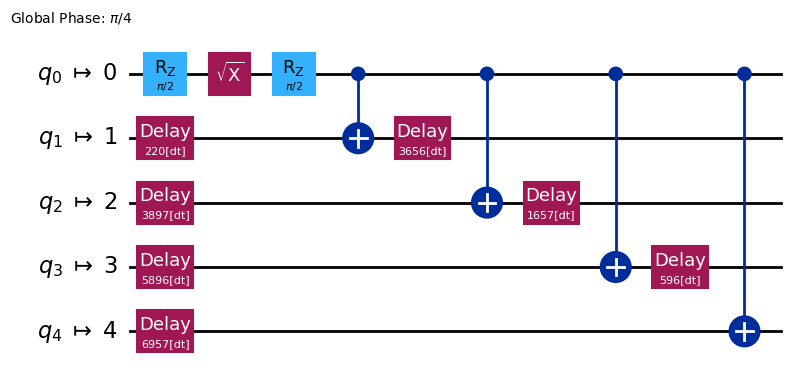

In [29]:
ghz = QuantumCircuit(5)
ghz.h(0)
ghz.cx(0, range(1, 5))


# Use fake backend
backend = GenericBackendV2(5)

# Run with optimization level 3 and 'asap' scheduling pass
pass_manager = generate_preset_pass_manager(
    optimization_level=3,
    backend=backend,
    scheduling_method="asap",
    seed_transpiler=1234,
)


circ = pass_manager.run(ghz)
circ.draw(output="mpl", idle_wires=False)

Transpile with pass managers

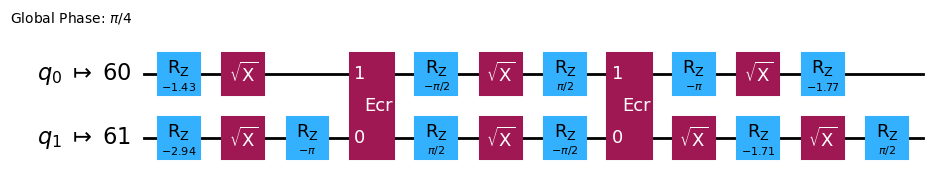

In [1]:
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime.fake_provider import FakeSherbrooke
from qiskit import QuantumRegister, QuantumCircuit

backend = FakeSherbrooke()
pass_manager = generate_preset_pass_manager(
    optimization_level=3, backend=backend
)

# Create a circuit
qubits = QuantumRegister(2, name="q")
circuit = QuantumCircuit(qubits)
a, b = qubits
circuit.h(a)
circuit.cx(a, b)
circuit.cx(b, a)

# Transpile it by calling the run method of the pass manager
transpiled = pass_manager.run(circuit)

# Draw it, excluding idle qubits from the diagram
transpiled.draw("mpl", idle_wires=False)

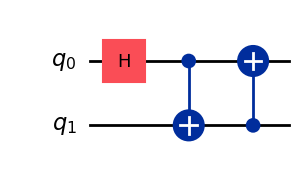

In [2]:
from qiskit.transpiler import PassManager
from qiskit import QuantumRegister, QuantumCircuit
from qiskit.transpiler.passes import (
    Collect2qBlocks,
    ConsolidateBlocks,
    UnitarySynthesis,
)

basis_gates = ["rx", "ry", "rxx"]
translate = PassManager(
    [
        Collect2qBlocks(),
        ConsolidateBlocks(basis_gates=basis_gates),
        UnitarySynthesis(basis_gates),
    ]
)
qubits = QuantumRegister(2, name="q")
circuit = QuantumCircuit(qubits)

a, b = qubits
circuit.h(a)
circuit.cx(a, b)
circuit.cx(b, a)

circuit.draw("mpl")

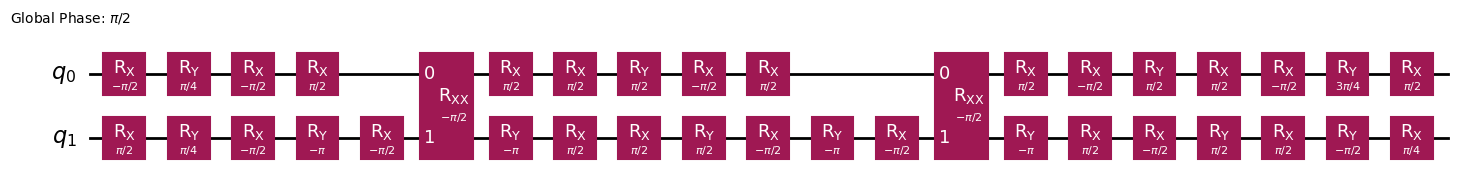

In [3]:
translated = translate.run(circuit)
translated.draw("mpl")